## **Studi Kasus: Dataset Harga Rumah Boston** <br>
Tujuan: Prediksi harga rumah berdasarkan variabel seperti tingkat kejahatan dan jumlah kamar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Latih data dengan model Regresi Linear
from sklearn.linear_model import LinearRegression
# Evaluasi model
from sklearn.metrics import mean_squared_error, r2_score
# Data di split untuk data training dan data testing
from sklearn.model_selection import train_test_split

In [ ]:
data = pd.read_csv(r'E:\DigitalentDA\Datasets\dataset7.csv')
df_boston = pd.DataFrame(data)

print(df_boston.head())
print(df_boston.info())
print(df_boston.describe())

      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float

In [ ]:
print(df_boston.isnull().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


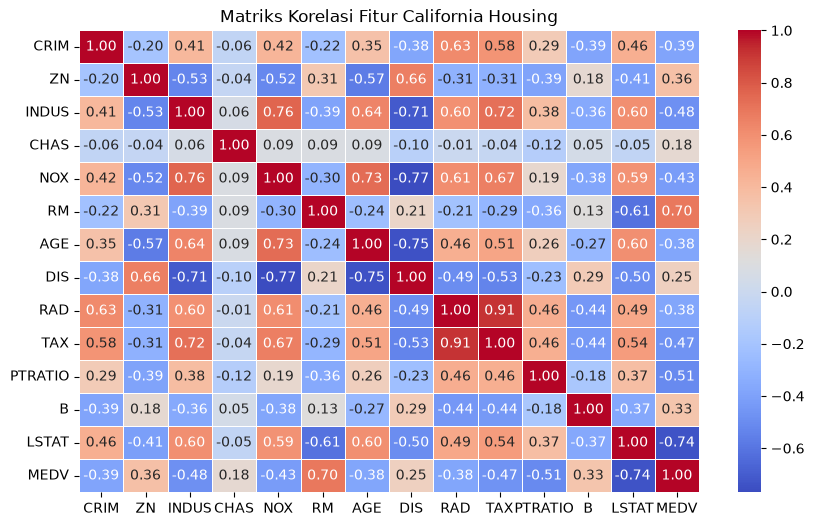

In [ ]:
num_df_boston = df_boston.select_dtypes(include=[np.number])
corr_boston = num_df_boston.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_boston, annot=True, cmap='coolwarm', fmt='.2f', linewidths='0.5')
plt.title("Matriks Korelasi Fitur California Housing")
plt.show()

RM   : average number of rooms per dwelling <br>
MEDV : Median value of owner-occupied homes in $1000's <br>
correlation: 0.70

In [ ]:
# Fitur
X2 = df_boston[['RM']]
# Target
y2 = df_boston['MEDV']

In [ ]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train2, y_train2)

y_pred2 = model.predict(X_test2)
mse = mean_squared_error(y_test2, y_pred2)

print(f"Mean Squared Error: {mse}")

Mean Squared Error: 46.144775347317264


In [ ]:
intercept2 = model.intercept_
slope2 = model.coef_[0]

print("--- Hasil Rumus Model ---")
print(f"Intercept (Beta 0): {intercept2:.2f}")
print(f"Slope/Koefisien (Beta 1): {slope2:.2f}")
print(f"\nPersamaan: Harga Rumah = {intercept2:.2f} + ({slope2:.2f} * RM)")

--- Hasil Rumus Model ---
Intercept (Beta 0): -36.25
Slope/Koefisien (Beta 1): 9.35

Persamaan: Harga Rumah = -36.25 + (9.35 * RM)


In [ ]:
r2_boston = r2_score(y_test2, y_pred2)
rmse_boston = np.sqrt(mean_squared_error(y_test2, y_pred2))

print("--- Evaluasi Model ---")
print(f"R-squared Score: {r2_boston:.4f}")
print(f"RMSE: ${rmse_boston:.2f}")

--- Evaluasi Model ---
R-squared Score: 0.3708
RMSE: $6.79


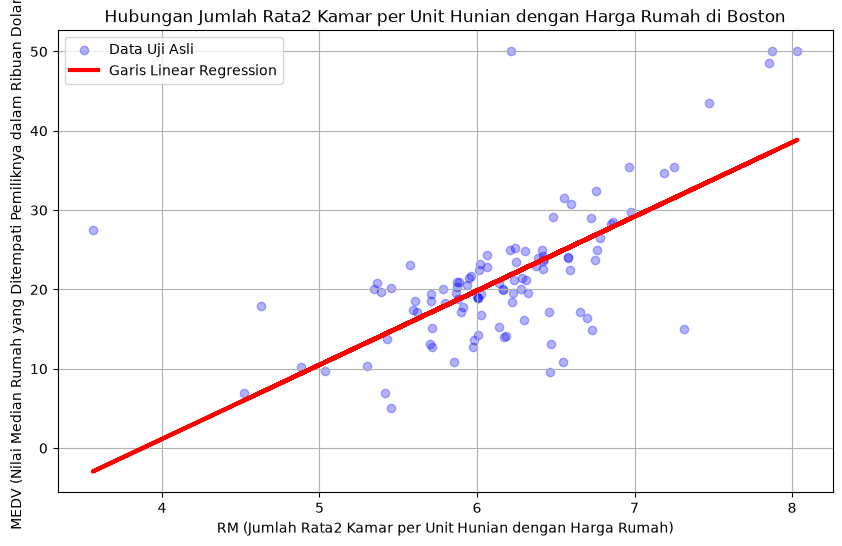

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test2, y_test2, color='blue', alpha=0.3, label='Data Uji Asli')
plt.plot(X_test2, y_pred2, color='red', linewidth=3, label='Garis Linear Regression')

plt.title('Hubungan Jumlah Rata2 Kamar per Unit Hunian dengan Harga Rumah di Boston')
plt.xlabel('RM (Jumlah Rata2 Kamar per Unit Hunian dengan Harga Rumah)')
plt.ylabel('MEDV (Nilai Median Rumah yang Ditempati Pemiliknya dalam Ribuan Dolar)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
df_compare2 = pd.DataFrame({
    'Nilai Asli (y_test)': y_test2.values,
    'Nilai Prediksi (y_pred)': y_pred2,
    'Error': abs(y_test2.values - y_pred2)
})

print(df_compare2.head(10))
print(df_compare2['Error'].describe())

   Nilai Asli (y_test)  Nilai Prediksi (y_pred)     Error
0                 23.6                23.732383  0.132383
1                 32.4                26.929502  5.470498
2                 13.6                19.684568  6.084568
3                 22.8                20.451129  2.348871
4                 16.1                22.619935  6.519935
5                 20.0                22.451666  2.451666
6                 17.8                19.039536  1.239536
7                 14.0                21.470094  7.470094
8                 19.6                21.984251  2.384251
9                 16.8                20.095894  3.295894
count    102.000000
mean       4.478336
std        5.132991
min        0.025866
25%        1.171808
50%        2.417958
75%        6.444435
max       30.457018
Name: Error, dtype: float64
